# Statistik-Labor Testat – NANUAG-Gesamtprojekt (Version 1)
**Wintersemester 2026/2027 – Gruppe 04**

***Hinweise:***
- Die Variablen unten sind bereits auf **Ihre Gruppe (04)** voreingestellt.
- Bitte überprüfen Sie Ihre Resultate laufend mit `Teilergebnisse_G04_V01.txt`.
- **Es wird dreimal abgegeben**, jeweils zusammen mit der zugehörigen Präsentation:
  Zwischenabgabe 1, Zwischenabgabe 2 und Endabgabe. Jede Abgabe besteht aus diesem (wachsenden)
  Notebook **und** einem PDF-Export davon, in Moodle.
  Dateiname je Abgabe: `Projekt_Gruppe04_<Nachnamen>_Zwischenabgabe1.ipynb`
  bzw. `..._Zwischenabgabe2.ipynb` bzw. `..._Endabgabe.ipynb`.
- Konkrete Wochentage/Uhrzeiten werden noch bekanntgegeben; siehe Terminplan für die Kalenderwochen.
- Geben Sie **niemals** die vollständige Tabelle mit 100.000 Zeilen aus — nutzen Sie `.head()`,
  `.sample()`, Aggregationen und Diagramme.
- Die vollständige Aufgabenstellung mit allen Teilaufgaben finden Sie in
  `Aufgabenstellung_Gruppe04.pdf`. Dieses Notebook ist das Arbeitsgerüst.

In [37]:
GRUPPENNUMMER = 4   # bereits auf Ihre Gruppe voreingestellt
VERSION = 1         # dieses Semester fuer alle Gruppen: Version 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

g = f"{GRUPPENNUMMER:02d}"
v = f"{VERSION:02d}"
pfad = f"Gruppe{g}/"
print("Arbeite mit Dateien aus:", pfad)

Arbeite mit Dateien aus: Gruppe04/


---
# Teil 1 – Personaldaten der NANUAG

## a) Daten einlesen

In [38]:
mitarbeiter = pd.read_csv(pfad + f"nanuag_mitarbeiter_G{g}_V{v}.csv",
                          sep=';', encoding='utf-8')
mitarbeiter.head()

,Personalnummer,Anrede,Vorname,Nachname,Geburtsdatum,Abteilung,Standort,Jahresgehalt,Fuehrungsposition
0,100000,Frau,Marie,Lange,11.05.1958,Logistik,Leipzig,50341.50,Nein
1,100001,Frau,Melanie,Zimmermann,21.09.2004,Finanzen,Essen,43721.03,Nein
2,100002,Frau,Melanie,Weber,18.12.1989,Produktion,Essen,46834.31,Nein
3,100003,Divers,Stefan,Jung,30.01.1991,Produktion,Essen,44877.24,Nein
4,100004,Frau,Birgit,Fuchs,15.06.1968,Logistik,Rostock,41075.25,Nein


## b) Datenbereinigung
Dokumentieren Sie Ihre Regeln in einer Tabelle (z. B. als DataFrame).

In [39]:

clean = mitarbeiter.copy()


heute = pd.Timestamp("2026-12-31")

geburt = pd.to_datetime(clean["Geburtsdatum"],format="%d.%m.%Y",errors="coerce")

# gehälter in zahlen umwandeln
gehalt = pd.to_numeric(clean["Jahresgehalt"],errors="coerce")
basis = gehalt[gehalt.notna() & (gehalt > 0)]

# bereinigungsregeln
regeln = {
    "Doppelte Personalnummer": clean["Personalnummer"].duplicated(keep="first"),

    "Ungültiges Geburtsdatum": geburt.isna(),

    "Zukünftiges Geburtsdatum": geburt.notna() & (geburt > heute),

    "Gehalt null oder negativ": gehalt.notna() & (gehalt <= 0),

    "Unplausibles Gehalt 999999.99": gehalt.eq(999999.99),
    
}

# ergebnis: treffer je regel
ergebnis = pd.DataFrame([
    {
        "Regel": name,
        "Betroffene Datensätze": int(maske.sum())
    }
    for name, maske in regeln.items()
])

display(ergebnis)


# ein datensatz wird nur einmal entfernt, auch wenn mehrere regeln zutreffen.
entfernen = pd.DataFrame(regeln).any(axis=1)
#nach iqr seperat weil sonst mehr als 1713 datensätze entfernt werden
q1 = basis.quantile(0.25)
q3 = basis.quantile(0.75)
iqr = q3 - q1
untergrenze = q1 - 1.5 * iqr
obergrenze = q3 + 1.5 * iqr

iqr = {
    "Gehaltsausreißer nach IQR-Regel": gehalt.notna() & ((gehalt < untergrenze) | (gehalt > obergrenze)) & clean["Fuehrungsposition"].eq("Nein"),
}

ergebnis = pd.DataFrame([
    {
        "Regel": name,
        "Betroffene Datensätze": int(maske.sum())
    }
    for name, maske in iqr.items()
])

display(ergebnis)

clean = clean.loc[~entfernen].copy()


,Regel,Betroffene Datensätze
0,Doppelte Personalnummer,285
1,Ungültiges Geburtsdatum,858
2,Zukünftiges Geburtsdatum,286
3,Gehalt null oder negativ,176
4,Unplausibles Gehalt 999999.99,109


,Regel,Betroffene Datensätze
0,Gehaltsausreißer nach IQR-Regel,931


## c) Alter bestimmen (Stichtag 31.12.2026)

In [40]:

geburt = pd.to_datetime(clean["Geburtsdatum"],format="%d.%m.%Y",errors="coerce")
clean["Alter"] = (
    heute.year - geburt.dt.year 
)
durchschnittsalter = clean["Alter"].mean()

print(f"Durchschnittsalter: {durchschnittsalter:.2f} Jahre")

Durchschnittsalter: 43.97 Jahre


## d) Explorative Analyse (Säulendiagramme, Tortendiagramme)

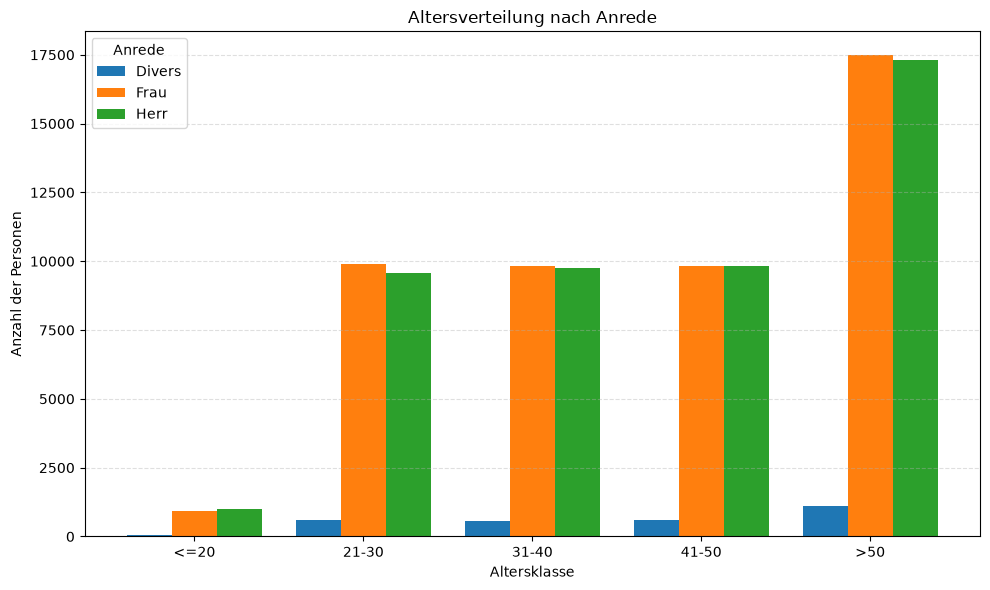

47432
47926
2929


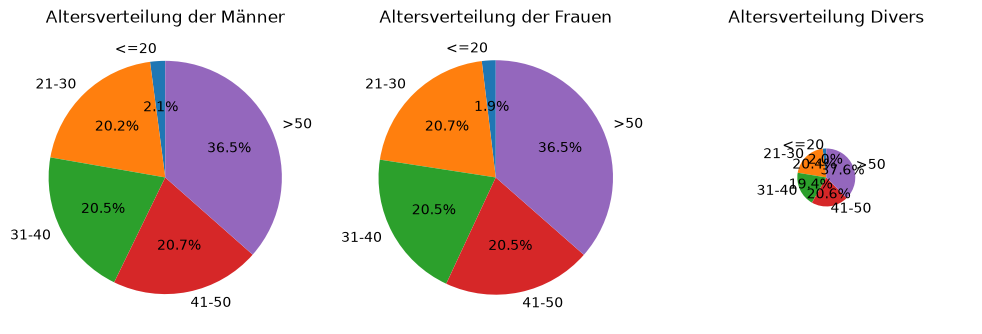

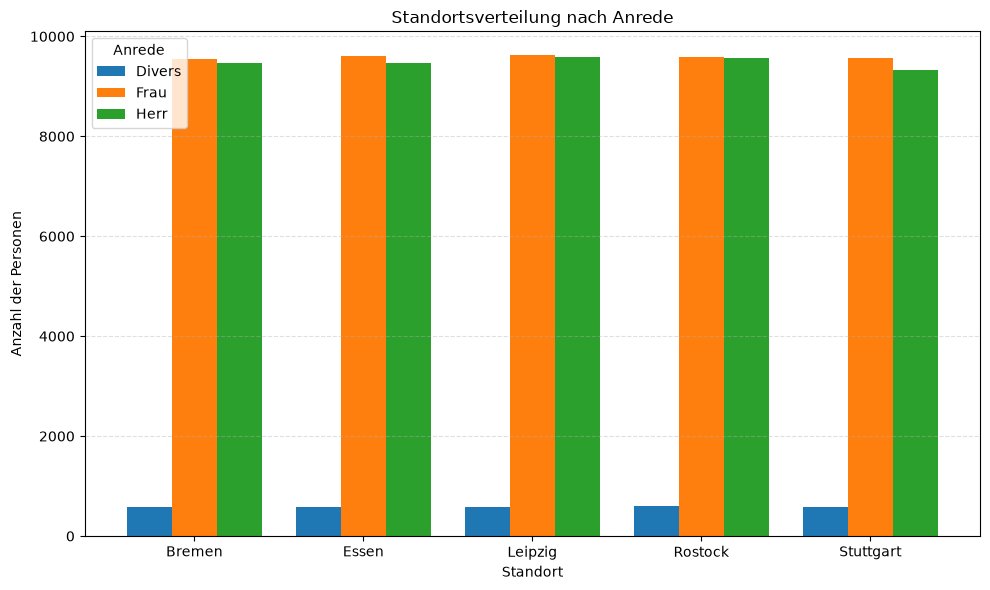

In [ ]:
gruppen = [0, 20, 30, 40, 50, 100]
labels = ["<=20", "21-30", "31-40", "41-50", ">50"]

clean["Altersklasse"] = pd.cut(
    clean["Alter"],
    bins=gruppen,
    labels=labels,
    right=True
)
bar = pd.crosstab(
    clean["Altersklasse"],
    clean["Anrede"]
)

bar = bar.reindex(labels, fill_value=0)

bar.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)
plt.title('Altersverteilung nach Anrede')
plt.xlabel('Altersklasse')
plt.ylabel('Anzahl der Personen')
plt.xticks(rotation=0)
plt.legend(title='Anrede')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

maenner = clean[clean["Anrede"] == "Herr"]["Altersklasse"].value_counts().reindex(labels, fill_value=0)
frauen = clean[clean["Anrede"] == "Frau"]["Altersklasse"].value_counts().reindex(labels, fill_value=0)
divers = clean[clean["Anrede"] == "Divers"]["Altersklasse"].value_counts().reindex(labels, fill_value=0)

n_maenner = maenner.sum()
n_frauen = frauen.sum()
n_divers = divers.sum()

max_n = max(n_maenner, n_frauen, n_divers)

fig, axes = plt.subplots(1, 3, figsize=(10, 6))

maenner.plot(
    kind="pie",
    ax=axes[0],
    autopct='%1.1f%%',
    startangle=90,
    radius=(n_maenner / max_n) ** 0.5
)
axes[0].set_title('Altersverteilung der Männer')
axes[0].set_ylabel('')

frauen.plot(
    kind='pie',
    ax=axes[1],
    autopct='%1.1f%%',
    startangle=90,
    radius=(n_frauen / max_n) ** 0.5
)
axes[1].set_title('Altersverteilung der Frauen')
axes[1].set_ylabel('')

divers.plot(
    kind="pie",
    ax=axes[2],
    autopct='%1.1f%%',
    startangle=90,
    radius=(n_divers / max_n) ** 0.5
)
axes[2].set_title('Altersverteilung Divers')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

bar = pd.crosstab(
    clean["Standort"],
    clean["Anrede"]
)
bar.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)
plt.title('Standortsverteilung nach Anrede')
plt.xlabel('Standort')
plt.ylabel('Anzahl der Personen')
plt.xticks(rotation=0)
plt.legend(title='Anrede')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## e) Kennzahlen (Alter und Jahresgehalt, gesamt / Herr / Frau)

In [42]:
merkmale = ['Alter', 'Jahresgehalt']

def kennzahlen(daten):
    ergebnis = {}

    for spalte in merkmale:
        x = daten[spalte].dropna()

        ergebnis[spalte] = {
            'Mittelwert': x.mean(),
            'Empirische Varianz': x.var(ddof=0),
            'Empirische Standardabweichung': x.std(ddof=0),
            'Median': x.median(),
            'Spannweite': x.max() - x.min()
        }

    return pd.DataFrame(ergebnis)

# 1. Gesamt
gesamt = kennzahlen(clean)

# 2. Getrennt nach Anrede
nach_anrede = {
    anrede: kennzahlen(gruppe)
    for anrede, gruppe in clean.groupby('Anrede')
}

# Ergebnisse ausgeben
print("GESAMT")
print(gesamt.to_string(float_format=lambda x: f"{x:.4f}"))

for anrede, tabelle in nach_anrede.items():
    print(f"\nANREDE: {anrede}")
    print(tabelle.to_string(float_format=lambda x: f"{x:.4f}"))

GESAMT
                                 Alter  Jahresgehalt
Mittelwert                     43.9689    48142.5840
Empirische Varianz            198.9445 80543680.3717
Empirische Standardabweichung  14.1048     8974.6131
Median                         44.0000    47501.8000
Spannweite                     48.0000    60513.4200

ANREDE: Divers
                                 Alter  Jahresgehalt
Mittelwert                     44.3230    50494.5853
Empirische Varianz            202.4631 87155784.0746
Empirische Standardabweichung  14.2290     9335.7262
Median                         44.0000    49872.9800
Spannweite                     48.0000    51862.1900

ANREDE: Frau
                                 Alter  Jahresgehalt
Mittelwert                     43.9151    45914.8086
Empirische Varianz            198.5199 66008017.5374
Empirische Standardabweichung  14.0897     8124.5318
Median                         44.0000    45443.9350
Spannweite                     48.0000    58418.9600

ANREDE: 

## f) Zusammenhangsanalyse: Pearson- und Spearman-Korrelation Alter/Jahresgehalt

## g) Diskussion: Erste Vermutung zum Gehaltsunterschied
*(Freitext-Antwort als Markdown-Zelle)*

*Ihre Antwort hier...*

---
# Teil 2 – Unternehmensentwicklung

## a) Daten einlesen und Streudiagramm

In [43]:
umsatz = pd.read_csv(pfad + f"nanuag_umsatz_G{g}_V{v}.txt", sep=r'\s+',
                      decimal=',', header=None, names=['Jahr','Umsatz_Mio_EUR'])
umsatz.head()

,Jahr,Umsatz_Mio_EUR
0,1994,28.133292
1,1995,30.608344
2,1996,26.740902
3,1997,41.030563
4,1998,49.415221


## b) Regressionsanalyse (5 Funktionstypen gemäß Anhang A – abhängig von gerader/ungerader Gruppennummer)

## c) Kreuzvalidierung (Training 1994–2018, Test 2019–2026): R²/RMSE je Modell auf Testdaten

## d) Modellwahl und Begründung (basierend auf b und c) + Residuenplot

## e) Diagramm mit optimaler Regressionskurve

## f) Prognose 2030 / 2035, Vergleich mit Polynom 6. Grades, Diskussion Extrapolation

---
# Teil 3 – Firmenlotterie „NANU-Glück“

## a) Erwartungswert und Standardabweichung von $X_{10}$ (vollständige Rechnung)

## b) $X_9, \dots, X_2$ tabellarisch

## c) Optimale Anzahl angekreuzter Zahlen + Diskussion Risiko vs. Erwartungswert

## d) Individuelle Aufgabe

In [44]:
with open(pfad + f"nanuag_lotterie_frage_G{g}_V{v}.txt", encoding='utf-8') as f:
    print(f.read())

Ein/e NANUAG-Mitarbeiter/in nimmt an 18 aufeinanderfolgenden Ziehungen der Firmenlotterie "NANU-Glück" teil. Bei jeder Ziehung kreuzt er/sie in seinem/ihrem Tippfeld 5 Zahlen an (Regeln wie in Teil 3 a)/b) beschrieben, Einsatz jeweils 2 €). Ein Teilnahme gilt als "Treffer", wenn bei dieser Ziehung ein Gewinn (Auszahlung > 0 €) erzielt wird.

Berechnen Sie die Wahrscheinlichkeit, dass der/die Mitarbeiter/in bei den 18 Ziehungen mindestens 2-mal einen Treffer erzielt.

Welche Verteilung/Funktion verwenden Sie hier? Welche Werte setzen Sie für die Parameter ein? (Hinweis: Sie benötigen dafür die Trefferwahrscheinlichkeit p aus Aufgabenteil a)/b) für 5 angekreuzte Zahlen.)


## e) Kombinationsspiel: $X_{10}+X_2$ gleichzeitig — Unabhängigkeitsdiskussion, Erwartungswert und Standardabweichung

---
# Teil 4 – Qualitätskontrolle in der Fertigung

## a) Daten einlesen und Kennzahlen (MR1, MR2, MR3)

In [45]:
mr1 = pd.read_csv(pfad + f"nanuag_qc_G{g}_V{v}_MR1.txt", sep=r'\s+', decimal=',', header=None, names=['MR1'])
mr2 = pd.read_csv(pfad + f"nanuag_qc_G{g}_V{v}_MR2.txt", sep=r'\s+', decimal=',', header=None, names=['MR2'])
mr3 = pd.read_csv(pfad + f"nanuag_qc_G{g}_V{v}_MR3.txt", sep=r'\s+', decimal=',', header=None, names=['MR3'])
mr1.describe(), mr2.describe(), mr3.describe()

(                 MR1
 count  100000.000000
 mean        6.681062
 std         2.557295
 min         2.937300
 25%         4.360100
 50%         4.854600
 75%         9.457500
 max        10.848600,
                  MR2
 count  100000.000000
 mean      892.000059
 std         1.899000
 min       883.846300
 25%       890.721900
 50%       891.999350
 75%       893.280100
 max       900.040800,
                  MR3
 count  100000.000000
 mean       74.300449
 std         0.389375
 min        72.456300
 25%        74.035900
 50%        74.300350
 75%        74.562900
 max        76.029700)

## b) Histogramme (mit begründeter Klassenwahl, z. B. Sturges / Freedman-Diaconis)

## c) Normalverteilung? (Histogramm + Q-Q-Plot oder Schiefe/Kurtosis)

## d) Dichtekurve für normalverteilte Messreihen einzeichnen + Skalierungsfaktor erläutern

## e) Formaler Normalverteilungstest (Shapiro-Wilk oder Kolmogorov-Smirnov)
*Hinweis: `scipy.stats.shapiro` ist für n > 5000 nicht mehr zuverlässig — ziehen Sie eine
Zufallsstichprobe (z. B. n=2000) und diskutieren Sie „statistische vs. praktische Signifikanz“
bei sehr großen Stichproben.*

---
# Teil 5 – Statistische Tests: Gehalt, Führung und Abteilungszugehörigkeit

## a) Gauß-Test (Einstichproben-Z-Test): MR2 gegen Sollmaß μ0=883,0, bekannt: σ0=1,8

## b) Zweistichproben-t-Test (Jahresgehalt Herr vs. Frau)

## c) Binomialtest (Frauenanteil Führungspositionen, $H_0: p=0{,}30$)

## d) Chi-Quadrat-Unabhängigkeitstest (Kreuztabelle Anrede × Abteilung)

## e) Mehrfachtestproblem: Bonferroni-Korrektur über die vier Tests a)–d) ($\alpha'=\alpha/4$)

## f) Management-Summary (max. 1 Seite)

*Ihre Zusammenfassung hier...*